## Might have to install this everytime but im not sure

In [1]:
pip install nba_api

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.7/261.7 kB 4.4 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


## I got most of the info on how to pull from the API from: https://github.com/swar/nba_api/blob/master/docs/examples/Basics.ipynb. There is a lot of documentation on how to use the API. 

### This one is for players but there is one similar for teams. I am basiscally just using this to get the player ID for steph curry. but you could do this for any player to get their ID. you could also do the same for team to get their team ID and pull data on that team

In [1]:
from nba_api.stats.static import players
# get_players returns a list of dictionaries, each representing a player.
nba_players = players.get_players()

In [12]:
steph = [player for player in nba_players if player["full_name"] == "Stephen Curry"][0]
stephID = steph['id']

### This is where i used the ID to pull stephs career stats. there is a list of enpoints in the above URL that could be used to pull different data

In [14]:
from nba_api.stats.endpoints import playercareerstats

# steph curry carrer stats
career = playercareerstats.PlayerCareerStats(player_id=stephID)
df = career.get_data_frames()[0]
df.head()

,PLAYER_ID,SEASON_ID,LEAGUE_ID,TEAM_ID,TEAM_ABBREVIATION,PLAYER_AGE,GP,GS,MIN,FGM,...,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PTS
0,201939,2009-10,00,1610612744,GSW,22.0,80,77,2896.0,528,...,0.885,48,308,356,472,152,19,243,252,1399
1,201939,2010-11,00,1610612744,GSW,23.0,74,74,2489.0,505,...,0.934,52,234,286,432,109,20,226,233,1373
2,201939,2011-12,00,1610612744,GSW,24.0,26,23,732.0,145,...,0.809,15,73,88,138,39,8,65,62,383
3,201939,2012-13,00,1610612744,GSW,25.0,78,78,2983.0,626,...,0.900,59,255,314,539,126,12,240,198,1786
4,201939,2013-14,00,1610612744,GSW,26.0,78,78,2846.0,652,...,0.885,46,288,334,666,128,14,294,194,1873


## The rest of this until the next markdown cell is just me fucking around with the data

In [16]:
df.sort_values('PLAYER_AGE')

,PLAYER_ID,SEASON_ID,LEAGUE_ID,TEAM_ID,TEAM_ABBREVIATION,PLAYER_AGE,GP,GS,MIN,FGM,...,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PTS
0,201939,2009-10,00,1610612744,GSW,22.0,80,77,2896.0,528,...,0.885,48,308,356,472,152,19,243,252,1399
1,201939,2010-11,00,1610612744,GSW,23.0,74,74,2489.0,505,...,0.934,52,234,286,432,109,20,226,233,1373
2,201939,2011-12,00,1610612744,GSW,24.0,26,23,732.0,145,...,0.809,15,73,88,138,39,8,65,62,383
3,201939,2012-13,00,1610612744,GSW,25.0,78,78,2983.0,626,...,0.900,59,255,314,539,126,12,240,198,1786
4,201939,2013-14,00,1610612744,GSW,26.0,78,78,2846.0,652,...,0.885,46,288,334,666,128,14,294,194,1873
5,201939,2014-15,00,1610612744,GSW,27.0,80,80,2613.0,653,...,0.914,56,285,341,619,163,16,249,158,1900
6,201939,2015-16,00,1610612744,GSW,28.0,79,79,2700.0,805,...,0.908,68,362,430,527,169,15,262,161,2375
7,201939,2016-17,00,1610612744,GSW,29.0,79,79,2639.0,675,...,0.898,61,292,353,524,142,17,239,183,1999
8,201939,2017-18,00,1610612744,GSW,30.0,51,51,1631.0,428,...,0.921,36,225,261,310,80,8,153,114,1346
9,201939,2018-19,00,1610612744,GSW,31.0,69,69,2331.0,632,...,0.916,45,324,369,361,92,25,192,166,1881


In [32]:
df.columns

Index(['PLAYER_ID', 'SEASON_ID', 'LEAGUE_ID', 'TEAM_ID', 'TEAM_ABBREVIATION',
       'PLAYER_AGE', 'GP', 'GS', 'MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A',
       'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST', 'STL',
       'BLK', 'TOV', 'PF', 'PTS', 'ppg', 'apg', 'spg', 'mpg'],
      dtype='object')

In [18]:
df['ppg'] = df['PTS'] / df['GP']
df['apg'] = df['AST'] / df['GP']
df['spg'] = df['STL']/ df['GP']
df['mpg'] = df['MIN'] / df['GP']

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

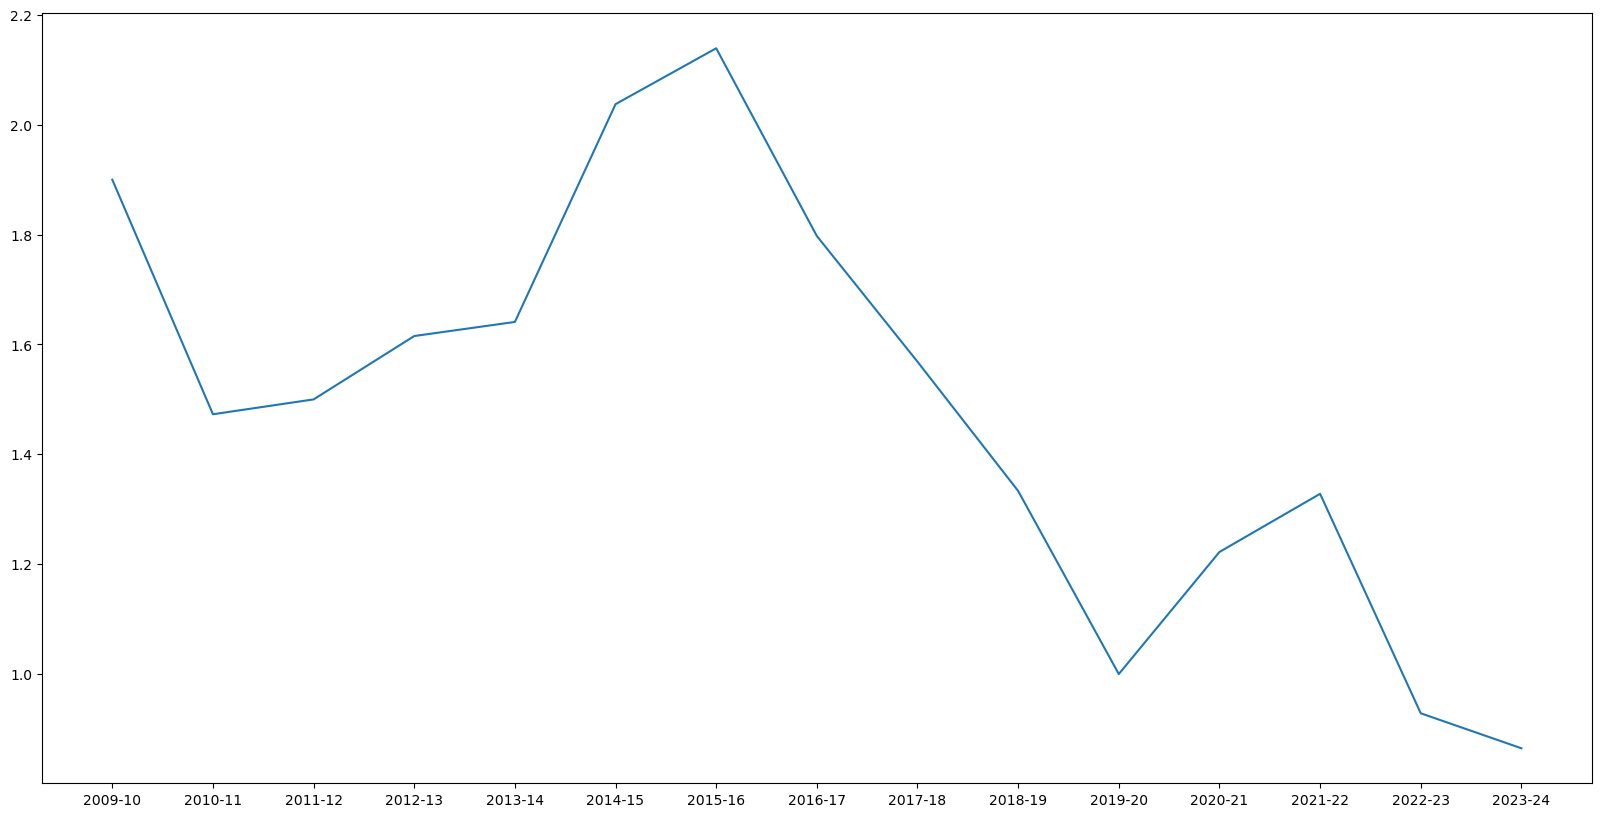

In [42]:
x = df['SEASON_ID']
y = df['spg']
fig = plt.figure(figsize=(20,10))
plt.plot(x,y)
plt.show()

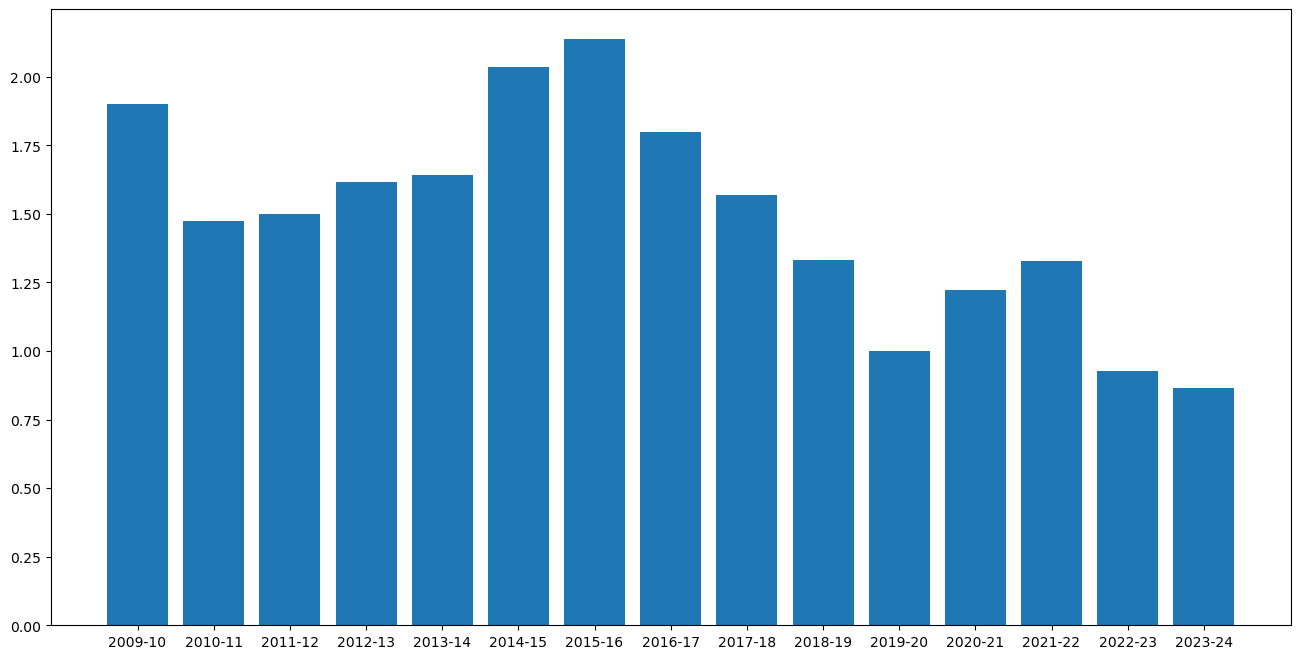

In [43]:
fig = plt.figure(figsize=(16, 8))
plt.bar(x,y)
plt.show()

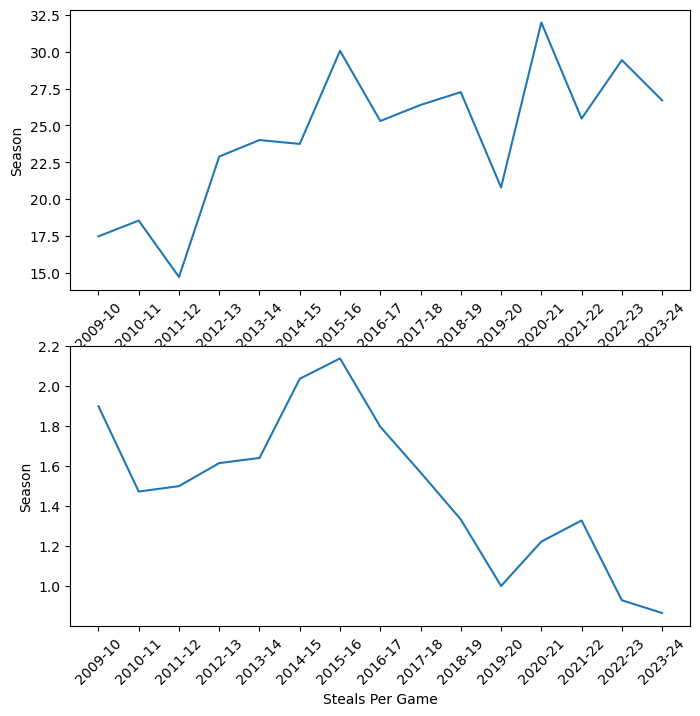

In [54]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8))
ax1.plot(df['SEASON_ID'], df['ppg'])
ax1.set_ylabel('Season')
ax1.set_xlabel('Points Per Game')
ax1.set_xticks(df['SEASON_ID'])  # Set the x-axis ticks

ax2.plot(df['SEASON_ID'], df['spg'])
ax2.set_ylabel('Season')
ax2.set_xlabel('Steals Per Game')
ax2.set_xticks(df['SEASON_ID'])  # Set the x-axis ticks

ax1.tick_params(axis='x', rotation=45)
ax2.tick_params(axis='x', rotation=45)

plt.show()

# Ok this is where i acually start to pull all of the player data for each game

### I found this endpoint from the URL. The reason I pulled from this end point was to get the game ID for every game so far during the season. I pulled this on 1/21. 

In [20]:
from nba_api.stats.endpoints import leaguegamelog
test = leaguegamelog.LeagueGameLog(season='2023-24')
game_list = test.get_data_frames()[0]
game_list.head()

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,...,DREB,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,VIDEO_AVAILABLE
0,22023,1610612747,LAL,Los Angeles Lakers,0022300061,2023-10-24,LAL @ DEN,L,240,41,...,31,44,23,5,4,12,18,107,-12,1
1,22023,1610612743,DEN,Denver Nuggets,0022300061,2023-10-24,DEN vs. LAL,W,240,48,...,33,42,29,9,6,12,15,119,12,1
2,22023,1610612756,PHX,Phoenix Suns,0022300062,2023-10-24,PHX @ GSW,W,240,42,...,43,60,23,5,7,19,22,108,4,1
3,22023,1610612744,GSW,Golden State Warriors,0022300062,2023-10-24,GSW vs. PHX,L,240,36,...,31,49,19,11,6,11,23,104,-4,1
4,22023,1610612764,WAS,Washington Wizards,0022300064,2023-10-25,WAS @ IND,L,240,44,...,34,45,28,6,9,14,11,120,-23,1


### I got this array of each unique game ID so I can use this to pull the box score data

In [19]:
game_IDs = game_list['GAME_ID'].unique()
game_IDs

array(['0022300061', '0022300062', '0022300070', '0022300074',
       '0022300066', '0022300073', '0022300072', '0022300071',
       '0022300069', '0022300067', '0022300068', '0022300065',
       '0022300063', '0022300064', '0022300075', '0022300076',
       '0022300086', '0022300078', '0022300079', '0022300085',
       '0022300087', '0022300083', '0022300082', '0022300084',
       '0022300081', '0022300080', '0022300077', '0022300092',
       '0022300089', '0022300090', '0022300091', '0022300088',
       '0022300094', '0022300093', '0022300095', '0022300100',
       '0022300099', '0022300098', '0022300096', '0022300097',
       '0022300111', '0022300107', '0022300110', '0022300109',
       '0022300108', '0022300106', '0022300105', '0022300104',
       '0022300102', '0022300101', '0022300103', '0022300112',
       '0022300113', '0022300114', '0022300127', '0022300126',
       '0022300125', '0022300124', '0022300123', '0022300121',
       '0022300122', '0022300120', '0022300117', '00223

### This is where I pull all of the box score data for the entire season. I imported and used time so that i wouldnt get blocked or so that i would be able to pull everything. I looped over the gameID array and pulled the boxscore data for that game then added it to the empty list. after it was done i concatinated the data into a dataframe

In [17]:
from nba_api.stats.endpoints import boxscoretraditionalv2
import time

# List to store each game's DataFrame
all_games_data = []


# Looping through each game ID and fetching box score data
for game_id in game_IDs:
    box_score = boxscoretraditionalv2.BoxScoreTraditionalV2(game_id=game_id)
    gameData = box_score.get_data_frames()[0]
    all_games_data.append(gameData)

    time.sleep(1)

    #player_stats = box_score.player_stats.get_data()
    #team_stats = box_score.team_stats.get_data()

# Concatenate all DataFrames into a single DataFrame
traditional_boxscore = pd.concat(all_games_data, ignore_index=True)

KeyboardInterrupt: 

In [6]:
import pandas as pd
traditional_boxscore = pd.concat(all_games_data, ignore_index=True)

In [55]:
game_list.to_csv('game_list.csv')

In [33]:
game_list.head(50)

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,...,DREB,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,VIDEO_AVAILABLE
0,22023,1610612747,LAL,Los Angeles Lakers,0022300061,2023-10-24,LAL @ DEN,L,240,41,...,31,44,23,5,4,12,18,107,-12,1
1,22023,1610612743,DEN,Denver Nuggets,0022300061,2023-10-24,DEN vs. LAL,W,240,48,...,33,42,29,9,6,12,15,119,12,1
2,22023,1610612756,PHX,Phoenix Suns,0022300062,2023-10-24,PHX @ GSW,W,240,42,...,43,60,23,5,7,19,22,108,4,1
3,22023,1610612744,GSW,Golden State Warriors,0022300062,2023-10-24,GSW vs. PHX,L,240,36,...,31,49,19,11,6,11,23,104,-4,1
4,22023,1610612764,WAS,Washington Wizards,0022300064,2023-10-25,WAS @ IND,L,240,44,...,34,45,28,6,9,14,11,120,-23,1
5,22023,1610612754,IND,Indiana Pacers,0022300064,2023-10-25,IND vs. WAS,W,240,56,...,41,51,38,10,8,12,23,143,23,1
6,22023,1610612737,ATL,Atlanta Hawks,0022300063,2023-10-25,ATL @ CHA,L,240,39,...,30,42,24,12,1,12,19,110,-6,1
7,22023,1610612766,CHA,Charlotte Hornets,0022300063,2023-10-25,CHA vs. ATL,W,240,43,...,39,51,34,5,3,19,21,116,6,1
8,22023,1610612738,BOS,Boston Celtics,0022300065,2023-10-25,BOS @ NYK,W,240,37,...,39,46,18,6,11,13,22,108,4,1
9,22023,1610612752,NYK,New York Knicks,0022300065,2023-10-25,NYK vs. BOS,L,240,36,...,30,47,24,9,0,11,22,104,-4,1


### After i looked at the output of the last pull i realized there was no date for each game. so i went back and got the other fields that i think i might need then merged the dataframes on the gameID field. 

#### One thing i didnt realize is that the game_date dataframe had duplicates in it. so i had to drop the duplicates. but becasue of this i lost the ability to make a column for home and away games. I will have to add this is another way some how. the commented out code is what i had originally tried to do. for some reason it produced 8412 null values for the match up column. Wasnt sure why and now it works. this is what Chat GPT said: If your merge resulted in 8,412 null values for the 'MATCHUP' column, it suggests that there were rows in traditional_boxscore for which no corresponding rows could be found in game_date on the basis of 'GAME_ID' and 'TEAM_ID'. There are several potential reasons for this: Mismatched IDs: There could be discrepancies in 'GAME_ID' or 'TEAM_ID' between the two datasets. For instance, if a 'GAME_ID' or 'TEAM_ID' in traditional_boxscore doesn't exactly match any 'GAME_ID' or 'TEAM_ID' in game_date, the merge operation won't find a corresponding row to join, resulting in null values for 'MATCHUP'. Data Completeness: If game_list (from which game_date is derived) does not cover all the games or teams present in traditional_boxscore, there will be rows in traditional_boxscore without a corresponding match in game_date. Formatting Issues: If the format of 'GAME_ID' or 'TEAM_ID' is different between the two datasets (e.g., one uses integers while the other uses strings, or if there are leading/trailing spaces), this can cause the merge to fail to find matches. Filtering in Game Date Creation: When creating game_date, if any filtering or data processing was done that inadvertently removed relevant rows, it could lead to mismatches during the merge. To diagnose the issue, you could: Check the unique values and data types of 'GAME_ID' and 'TEAM_ID' in both datasets to ensure they align. Investigate a few specific instances where the merge resulted in null values to see if you can identify a pattern or reason. Ensure that game_list is comprehensive and includes all games and teams present in traditional_boxscore.

In [58]:
#game_date = game_list[['GAME_ID', 'GAME_DATE', 'MATCHUP', 'TEAM_ID']]
#game_date_cleaned = game_date.drop_duplicates(subset='GAME_ID', keep='first')
#mergedData = pd.merge(traditional_boxscore, game_date_cleaned, how='left', on=['GAME_ID', 'TEAM_ID'])
#mergedData

combined_df_refined = pd.merge(traditional_boxscore, game_list[['GAME_ID', 'TEAM_ID', 'MATCHUP']], on=['GAME_ID', 'TEAM_ID'], how='left')
combined_df_refined.head()

,GAME_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_CITY,PLAYER_ID,PLAYER_NAME,NICKNAME,START_POSITION,COMMENT,MIN,...,DREB,REB,AST,STL,BLK,TO,PF,PTS,PLUS_MINUS,MATCHUP
0,0022300061,1610612747,LAL,Los Angeles,1627752,Taurean Prince,Taurean,F,,29.000000:53,...,2.0,3.0,1.0,0.0,1.0,1.0,0.0,18.0,-14.0,LAL @ DEN
1,0022300061,1610612747,LAL,Los Angeles,2544,LeBron James,LeBron,F,,29.000000:01,...,7.0,8.0,5.0,1.0,0.0,0.0,1.0,21.0,7.0,LAL @ DEN
2,0022300061,1610612747,LAL,Los Angeles,203076,Anthony Davis,Anthony,C,,34.000000:09,...,7.0,8.0,4.0,0.0,2.0,2.0,3.0,17.0,-17.0,LAL @ DEN
3,0022300061,1610612747,LAL,Los Angeles,1630559,Austin Reaves,Austin,G,,31.000000:20,...,4.0,8.0,4.0,2.0,0.0,2.0,2.0,14.0,-14.0,LAL @ DEN
4,0022300061,1610612747,LAL,Los Angeles,1626156,D'Angelo Russell,D'Angelo,G,,36.000000:11,...,4.0,4.0,7.0,1.0,0.0,3.0,3.0,11.0,1.0,LAL @ DEN


In [62]:
combined_df_refined.to_csv('All_NBA_Games_Up_to_01_22_2024.csv')

In [152]:
combined_data2.to_csv('All_NBA_Games_Up_to_01_21_2024.csv')

In [154]:
combined_data2.columns

Index(['GAME_ID', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_CITY', 'PLAYER_ID',
       'PLAYER_NAME', 'NICKNAME', 'START_POSITION', 'COMMENT', 'MIN', 'FGM',
       'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT',
       'OREB', 'DREB', 'REB', 'AST', 'STL', 'BLK', 'TO', 'PF', 'PTS',
       'PLUS_MINUS', 'GAME_DATE', 'MATCHUP', 'WL'],
      dtype='object')

In [3]:
import pandas as pd
df = pd.read_csv('All_NBA_Games_Up_to_01_21_2024.csv')
player_names = df.PLAYER_NAME.unique()

### This is where i am pulling all the advanced box score data and not jsut the tradisional stats. this is pretty much a copy of the above cells but just changed the API endpoint. I also asked Chat GPT to make the code better for me and thats why there is try: and exept in the code. 

In [63]:
from nba_api.stats.endpoints import boxscoreadvancedv2
import time
player_advanced_stats = []

# Looping through each game ID and fetching box score data
for game_id in game_IDs:
    try:
        # Fetch advanced box score data for the game
        advanced_box_score = boxscoreadvancedv2.BoxScoreAdvancedV2(game_id=game_id)
        advancedGameData = advanced_box_score.get_data_frames()[0]

        # Append the DataFrame to the list
        player_advanced_stats.append(advancedGameData)
    except Exception as e:
        print(f"Error fetching data for game ID {game_id}: {e}")

    # Sleep to avoid hitting API rate limits
    time.sleep(1)

# Concatenate all DataFrames into a single DataFrame
combined_advanced_data = pd.concat(player_advanced_stats, ignore_index=True)
combined_advanced_data.head(50)

,GAME_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_CITY,PLAYER_ID,PLAYER_NAME,NICKNAME,START_POSITION,COMMENT,MIN,...,TM_TOV_PCT,EFG_PCT,TS_PCT,USG_PCT,E_USG_PCT,E_PACE,PACE,PACE_PER40,POSS,PIE
0,0022300061,1610612747,LAL,Los Angeles,1627752,Taurean Prince,Taurean,F,,29.000000:53,...,9.1,1.000,1.014,0.133,0.135,105.31,102.00,85.00,63,0.128
1,0022300061,1610612747,LAL,Los Angeles,2544,LeBron James,LeBron,F,,29.000000:01,...,0.0,0.656,0.639,0.225,0.245,97.19,97.62,81.35,60,0.189
2,0022300061,1610612747,LAL,Los Angeles,203076,Anthony Davis,Anthony,C,,34.000000:09,...,8.0,0.382,0.453,0.259,0.259,105.02,100.50,83.75,71,0.082
3,0022300061,1610612747,LAL,Los Angeles,1630559,Austin Reaves,Austin,G,,31.000000:20,...,10.0,0.409,0.497,0.203,0.205,106.13,102.64,85.53,67,0.088
4,0022300061,1610612747,LAL,Los Angeles,1626156,D'Angelo Russell,D'Angelo,G,,36.000000:11,...,13.0,0.417,0.427,0.186,0.200,97.50,96.84,80.70,74,0.047
5,0022300061,1610612747,LAL,Los Angeles,1629060,Rui Hachimura,Rui,,,14.000000:38,...,0.0,0.300,0.300,0.244,0.251,106.69,103.28,86.07,32,-0.019
6,0022300061,1610612747,LAL,Los Angeles,1629216,Gabe Vincent,Gabe,,,22.000000:18,...,16.7,0.375,0.375,0.185,0.197,88.94,89.33,74.44,42,-0.007
7,0022300061,1610612747,LAL,Los Angeles,1629637,Jaxson Hayes,Jaxson,,,6.000000:54,...,0.0,0.000,0.000,0.000,0.000,82.64,86.96,72.46,12,0.000
8,0022300061,1610612747,LAL,Los Angeles,1629629,Cam Reddish,Cam,,,17.000000:38,...,0.0,0.625,0.717,0.122,0.133,92.17,95.27,79.40,36,0.088
9,0022300061,1610612747,LAL,Los Angeles,1626174,Christian Wood,Christian,,,15.000000:28,...,16.7,0.750,0.717,0.182,0.196,85.10,85.34,71.12,28,0.100


In [64]:
combined_advanced_data.to_csv('All_NBA_Games_Up_to_01_22_2024_advanced_stats.csv')

In [22]:
combined_advanced_data['GAME_ID'] = combined_advanced_data['GAME_ID'].astype(int)


## Ok so this is something i am going to have to figure out. i need to merge these two dataframs where i dont have duplicates

In [24]:
combined_stats = pd.merge(df, combined_advanced_data, on=['GAME_ID', 'PLAYER_ID'])
combined_stats.head(50)

,Unnamed: 0,GAME_ID,TEAM_ID_x,TEAM_ABBREVIATION_x,TEAM_CITY_x,PLAYER_ID,PLAYER_NAME_x,NICKNAME_x,START_POSITION_x,COMMENT_x,...,TM_TOV_PCT,EFG_PCT,TS_PCT,USG_PCT,E_USG_PCT,E_PACE,PACE,PACE_PER40,POSS,PIE
0,0,22300062,1610612756,PHX,Phoenix,1629006,Josh Okogie,Josh,F,NaN,...,16.7,0.833,0.86,0.131,0.131,107.69,104.69,87.24,68,0.132
1,1,22300062,1610612756,PHX,Phoenix,201142,Kevin Durant,Kevin,F,NaN,...,6.9,0.341,0.372,0.292,0.290,102.91,99.18,82.65,75,0.085
2,2,22300062,1610612756,PHX,Phoenix,203994,Jusuf Nurkic,Jusuf,C,NaN,...,7.7,0.688,0.751,0.139,0.138,103.82,99.92,83.27,58,0.19
3,3,22300062,1610612756,PHX,Phoenix,1628960,Grayson Allen,Grayson,G,NaN,...,11.1,0.0,0.0,0.130,0.132,105.17,103.24,86.04,43,-0.103
4,4,22300062,1610612756,PHX,Phoenix,1626164,Devin Booker,Devin,G,NaN,...,16.7,0.69,0.717,0.292,0.290,106.86,103.23,86.02,79,0.199
5,5,22300062,1610612756,PHX,Phoenix,201569,Eric Gordon,Eric,NaN,NaN,...,5.6,0.313,0.313,0.207,0.212,105.49,103.13,85.94,68,0.008
6,6,22300062,1610612756,PHX,Phoenix,1629234,Drew Eubanks,Drew,NaN,NaN,...,30.0,0.333,0.42,0.160,0.168,107.11,106.07,88.39,43,0.067
7,7,22300062,1610612756,PHX,Phoenix,1629139,Yuta Watanabe,Yuta,NaN,NaN,...,16.7,0.8,0.8,0.136,0.140,105.66,103.36,86.13,39,0.143
8,8,22300062,1610612756,PHX,Phoenix,1630692,Jordan Goodwin,Jordan,NaN,NaN,...,22.2,0.25,0.25,0.182,0.189,98.28,96.45,80.38,29,0.127
9,9,22300062,1610612756,PHX,Phoenix,1629642,Nassir Little,Nassir,NaN,NaN,...,0.0,1.5,1.5,0.100,0.100,131.18,124.86,104.05,7,0.308


In [25]:
combined_stats.to_csv('All_NBA_Games_Up_to_01_21_2024_TRADITIONAL_AND_ADVANCED_STATS.csv')

In [4]:
game_list.head(40)

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,...,DREB,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,VIDEO_AVAILABLE
0,22023,1610612747,LAL,Los Angeles Lakers,0022300061,2023-10-24,LAL @ DEN,L,240,41,...,31,44,23,5,4,12,18,107,-12,1
1,22023,1610612743,DEN,Denver Nuggets,0022300061,2023-10-24,DEN vs. LAL,W,240,48,...,33,42,29,9,6,12,15,119,12,1
2,22023,1610612756,PHX,Phoenix Suns,0022300062,2023-10-24,PHX @ GSW,W,240,42,...,43,60,23,5,7,19,22,108,4,1
3,22023,1610612744,GSW,Golden State Warriors,0022300062,2023-10-24,GSW vs. PHX,L,240,36,...,31,49,19,11,6,11,23,104,-4,1
4,22023,1610612753,ORL,Orlando Magic,0022300066,2023-10-25,ORL vs. HOU,W,240,42,...,40,57,19,8,6,16,20,116,30,1
5,22023,1610612746,LAC,LA Clippers,0022300074,2023-10-25,LAC vs. POR,W,240,47,...,31,45,36,11,7,18,20,123,12,1
6,22023,1610612757,POR,Portland Trail Blazers,0022300074,2023-10-25,POR @ LAC,L,240,44,...,25,40,20,10,4,18,20,111,-12,1
7,22023,1610612764,WAS,Washington Wizards,0022300064,2023-10-25,WAS @ IND,L,240,44,...,34,45,28,6,9,14,11,120,-23,1
8,22023,1610612754,IND,Indiana Pacers,0022300064,2023-10-25,IND vs. WAS,W,240,56,...,41,51,38,10,8,12,23,143,23,1
9,22023,1610612737,ATL,Atlanta Hawks,0022300063,2023-10-25,ATL @ CHA,L,240,39,...,30,42,24,12,1,12,19,110,-6,1


In [ ]:
from nba_api.stats.static import players
# get_players returns a list of dictionaries, each representing a player.
nba_players = players.get_players()

steph = [player for player in nba_players if player["full_name"] == "Stephen Curry"][0]
stephID = steph['id']

from nba_api.stats.endpoints import playercareerstats

# steph curry carrer stats
career = playercareerstats.PlayerCareerStats(player_id=stephID)
df = career.get_data_frames()[0]
df.head()

# Get team ID
from nba_api.stats.static import teams
nba_teams = teams.get_teams()

spurs = [team for team in nba_teams if team["full_name"] == "San Antonio Spurs"][0]